# Phase 5: Models and Evaluation
Goal: score every account with two detectors (z-score and Isolation Forest),
flag the top 3% for each, and grade them with the hidden labels.
Labels are used only for grading, never for scoring.

In [1]:
import numpy as np
import pandas as pd

# What the models see: the scaled features from Phase 4
X = pd.read_csv("../data/feature_matrix.csv", index_col="account_id")

# What only the grader sees: the hidden labels
labels = pd.read_csv("../data/labels.csv", index_col="account_id")

print("Feature matrix shape:", X.shape)
print("Labels shape:", labels.shape)
print("Same accounts in the same order:", (X.index == labels.index).all())

X.head()

Feature matrix shape: (3099, 5)
Labels shape: (3099, 3)
Same accounts in the same order: True


,account_age_days,trades_per_day,spike_ratio,linked_account_count,timing_regularity
account_id,,,,,
ACC00000,-0.892119,0.091013,-0.868948,-0.399175,-0.438372
ACC00001,-0.203933,-0.543359,0.345313,0.767847,-1.606399
ACC00002,-1.546086,0.034004,-0.627829,-0.399175,1.288612
ACC00003,0.594516,-1.248698,0.275533,-0.399175,-0.156966
ACC00004,-0.279975,-0.920124,0.075838,-0.399175,1.199949


## Method A: Z-score baseline
The scaled features are already z-scores (mean 0, std 1).
Suspicion score = the largest absolute z-score across the 5 features.

In [2]:
# Absolute z-score for every feature, then take the biggest one per account
zscore_scores = X.abs().max(axis=1)

print(zscore_scores.describe())

# Which accounts look most suspicious to this rule?
zscore_scores.sort_values(ascending=False).head(10)

count    3099.000000
mean        1.457429
std         1.120941
min         0.399175
25%         0.979080
50%         1.317958
75%         1.640103
max        13.605085
dtype: float64


account_id
ACC02629    13.605085
ACC02593    13.605085
ACC02831    12.871253
ACC01464    12.644390
ACC00526    12.582128
ACC01903    12.438063
ACC02370    12.174458
ACC02495    11.862040
ACC01409    11.857417
ACC02263    11.356344
dtype: float64

## Method B: Isolation Forest
Builds many random trees. Unusual accounts get isolated in fewer splits.
We do NOT pass the true anomaly rate (contamination) because that would be
peeking at the labels. We only use the scores and apply the 3% budget ourselves.

In [3]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=100, random_state=42)
iso.fit(X)

# score_samples gives HIGHER = MORE NORMAL, so flip the sign
# so that higher = more suspicious, like our z-score method
iso_scores = pd.Series(-iso.score_samples(X), index=X.index)

print(iso_scores.describe())

iso_scores.sort_values(ascending=False).head(10)

count    3099.000000
mean        0.443140
std         0.052565
min         0.371642
25%         0.406745
50%         0.431922
75%         0.466280
max         0.747424
dtype: float64


account_id
ACC02495    0.747424
ACC02831    0.725191
ACC02370    0.720040
ACC00526    0.717388
ACC00267    0.713134
ACC02263    0.705519
ACC03036    0.705141
ACC01446    0.704109
ACC02802    0.703449
ACC01464    0.701204
dtype: float64

## Apply the 3% alert budget
Analysts can review about 3% of accounts, so we flag the top 3% by score
for each method. Same number of flags for both = fair comparison.

In [4]:
BUDGET = 0.03
n_flag = int(round(BUDGET * len(X)))   # 3% of 3099 accounts
print("Accounts to flag per method:", n_flag)

def flag_top(scores, n):
    """Return a True/False Series: True for the n highest-scoring accounts."""
    top_accounts = scores.sort_values(ascending=False).head(n).index
    return pd.Series(scores.index.isin(top_accounts), index=scores.index)

zscore_flagged = flag_top(zscore_scores, n_flag)
iso_flagged = flag_top(iso_scores, n_flag)

print("Z-score flagged:", zscore_flagged.sum())
print("Isolation Forest flagged:", iso_flagged.sum())
print("Flagged by both:", (zscore_flagged & iso_flagged).sum())

Accounts to flag per method: 93
Z-score flagged: 93
Isolation Forest flagged: 93
Flagged by both: 67


## Grading with the hidden labels
- Precision = of the accounts we flagged, how many were truly abusive?
- Recall = of all truly abusive accounts, how many did we catch?
- F1 = one number that balances the two.
Labels are used here for grading only.

In [5]:
is_abusive = labels["is_anomaly"].astype(bool)
total_abusive = is_abusive.sum()
print("Truly abusive accounts:", total_abusive)

def grade(flagged, name):
    caught = (flagged & is_abusive).sum()      # flagged AND truly abusive
    precision = caught / flagged.sum()
    recall = caught / total_abusive
    f1 = 2 * precision * recall / (precision + recall)
    print(f"{name}: caught {caught}, precision {precision:.3f}, recall {recall:.3f}, F1 {f1:.3f}")
    return precision, recall, f1

grade(zscore_flagged, "Z-score         ")
grade(iso_flagged,    "Isolation Forest")

Truly abusive accounts: 99
Z-score         : caught 84, precision 0.903, recall 0.848, F1 0.875
Isolation Forest: caught 66, precision 0.710, recall 0.667, F1 0.688


(np.float64(0.7096774193548387),
 np.float64(0.6666666666666666),
 np.float64(0.6875))

## Where does each method catch or miss?
Recall broken down by abuse type, and by obvious vs. subtle.

In [6]:
# Put the labels and both flags in one table for grading
results = labels.copy()
results["zscore_flagged"] = zscore_flagged
results["iso_flagged"] = iso_flagged

# Only look at truly abusive accounts
abusive = results[results["is_anomaly"] == 1]

print("Recall by abuse type")
print(abusive.groupby("anomaly_type")[["zscore_flagged", "iso_flagged"]].mean().round(3))

print("\nRecall by difficulty")
print(abusive.groupby("difficulty")[["zscore_flagged", "iso_flagged"]].mean().round(3))

print("\nRecall by type AND difficulty")
print(abusive.groupby(["anomaly_type", "difficulty"])[["zscore_flagged", "iso_flagged"]].mean().round(3))

Recall by abuse type
               zscore_flagged  iso_flagged
anomaly_type                              
bot                     0.545        0.152
multi_account           1.000        0.848
trial_abuse             1.000        1.000

Recall by difficulty
            zscore_flagged  iso_flagged
difficulty                             
obvious              1.000        0.745
subtle               0.688        0.583

Recall by type AND difficulty
                          zscore_flagged  iso_flagged
anomaly_type  difficulty                             
bot           obvious              1.000        0.235
              subtle               0.062        0.062
multi_account obvious              1.000        1.000
              subtle               1.000        0.688
trial_abuse   obvious              1.000        1.000
              subtle               1.000        1.000


## One function for the whole experiment
Score with both methods, flag the top 3%, and grade with the labels.
Returns one row per method, so we can repeat it for different seeds.

In [7]:
def run_experiment(X, labels, seed):
    n_flag = int(round(BUDGET * len(X)))
    is_abusive = labels["is_anomaly"].astype(bool)
    abusive = labels[is_abusive]

    # Score with both methods (no labels used here)
    z_scores = X.abs().max(axis=1)
    iso = IsolationForest(n_estimators=100, random_state=seed).fit(X)
    iso_scores = pd.Series(-iso.score_samples(X), index=X.index)

    rows = []
    for name, scores in [("zscore", z_scores), ("isolation_forest", iso_scores)]:
        flagged = flag_top(scores, n_flag)

        # Grade with the labels
        caught = (flagged & is_abusive).sum()
        precision = caught / n_flag
        recall = caught / is_abusive.sum()
        row = {"seed": seed, "method": name,
               "precision": precision, "recall": recall,
               "f1": 2 * precision * recall / (precision + recall)}

        flagged_abusive = flagged[abusive.index]
        for t in ["trial_abuse", "multi_account", "bot"]:
            row["recall_" + t] = flagged_abusive[abusive["anomaly_type"] == t].mean()
        for d in ["obvious", "subtle"]:
            row["recall_" + d] = flagged_abusive[abusive["difficulty"] == d].mean()

        rows.append(row)

    return pd.DataFrame(rows), iso

# Test: with seed 42 on our current data, we should get the same numbers as before
table, _ = run_experiment(X, labels, seed=42)
table.round(3)

,seed,method,precision,recall,f1,recall_trial_abuse,recall_multi_account,recall_bot,recall_obvious,recall_subtle
0,42,zscore,0.903,0.848,0.875,1.0,1.000,0.545,1.000,0.688
1,42,isolation_forest,0.710,0.667,0.688,1.0,0.848,0.152,0.745,0.583


## Is it luck? Repeat with 5 random seeds
For each seed: generate new data -> build features -> scale -> score -> grade.
Report the mean and spread (std) across the 5 runs.

In [8]:
import sys
sys.path.append("../src")   # so the notebook can import the Phase 2 and 4 code

from generate_data import load_config, build_dataset
from features import build_features, fit_scaler, prepare_for_model

seeds = [1, 2, 3, 4, 5]
all_results = []

for seed in seeds:
    config = load_config()
    config["seed"] = seed                      # new seed = new dataset

    raw, labels_s = build_dataset(config)      # Phase 2 generator
    labels_s = labels_s.set_index("account_id")

    feats = build_features(raw)                # Phase 4 pipeline
    scaler = fit_scaler(feats)
    X_s = prepare_for_model(feats, scaler)

    table, _ = run_experiment(X_s, labels_s, seed)   # Phase 5 scoring and grading
    all_results.append(table)

all_results = pd.concat(all_results, ignore_index=True)

# Every seed, every method
print(all_results.round(3).to_string())

# Mean and spread per method
by_method = all_results.drop(columns="seed").groupby("method")
print("\nMEAN over 5 seeds")
print(by_method.mean().round(3).to_string())
print("\nSTD over 5 seeds")
print(by_method.std().round(3).to_string())

   seed            method  precision  recall     f1  recall_trial_abuse  recall_multi_account  recall_bot  recall_obvious  recall_subtle
0     1            zscore      0.892   0.838  0.865                1.00                 1.000       0.515           1.000          0.667
1     1  isolation_forest      0.710   0.667  0.688                0.97                 0.909       0.121           0.745          0.583
2     2            zscore      0.892   0.838  0.865                1.00                 1.000       0.515           1.000          0.667
3     2  isolation_forest      0.688   0.646  0.667                1.00                 0.848       0.091           0.725          0.562
4     3            zscore      0.892   0.838  0.865                1.00                 1.000       0.515           1.000          0.667
5     3  isolation_forest      0.699   0.657  0.677                0.97                 1.000       0.000           0.667          0.646
6     4            zscore      0.892   0.

## Save results and the trained model
- `data/model_comparison.csv`: mean and std over the 5 seeds, for the README table
- `artifacts/isolation_forest.pkl`: Isolation Forest trained on the main dataset, for the API

In [9]:
import joblib

# 1) Results table: mean and std for every metric, one row per method
metrics = all_results.drop(columns="seed").groupby("method")
summary = metrics.mean().add_suffix("_mean").join(metrics.std().add_suffix("_std")).round(3)
summary.to_csv("../data/model_comparison.csv")
print(summary.T)

# 2) Train the final Isolation Forest on the main feature matrix and save it
iso_final = IsolationForest(n_estimators=100, random_state=42).fit(X)
joblib.dump(iso_final, "../artifacts/isolation_forest.pkl")

# 3) Check that the saved model gives identical scores when reloaded
loaded = joblib.load("../artifacts/isolation_forest.pkl")
print("Reloaded model gives identical scores:",
      np.allclose(loaded.score_samples(X), iso_final.score_samples(X)))

method                     isolation_forest  zscore
precision_mean                        0.710   0.890
recall_mean                           0.667   0.836
f1_mean                               0.688   0.862
recall_trial_abuse_mean               0.988   1.000
recall_multi_account_mean             0.891   0.994
recall_bot_mean                       0.121   0.515
recall_obvious_mean                   0.737   1.000
recall_subtle_mean                    0.592   0.662
precision_std                         0.017   0.005
recall_std                            0.016   0.005
f1_std                                0.016   0.005
recall_trial_abuse_std                0.017   0.000
recall_multi_account_std              0.066   0.014
recall_bot_std                        0.083   0.000
recall_obvious_std                    0.045   0.000
recall_subtle_std                     0.032   0.009
Reloaded model gives identical scores: True


## Result charts
Bars show the mean over 5 seeds. Black lines on chart 1 show the spread (std).

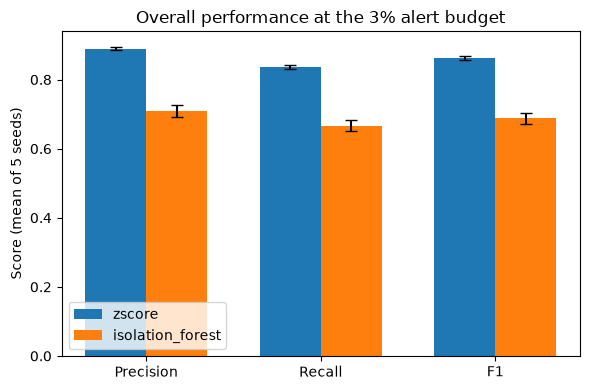

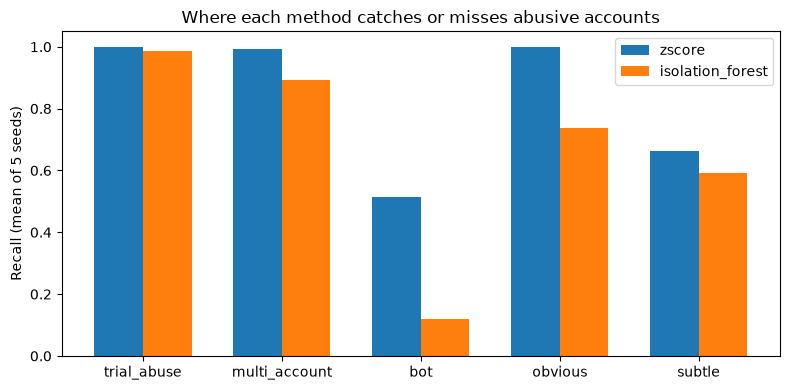

In [10]:
import matplotlib.pyplot as plt

methods = ["zscore", "isolation_forest"]
width = 0.35

# Chart 1: overall precision, recall, F1
names = ["precision", "recall", "f1"]
x = np.arange(len(names))
plt.figure(figsize=(6, 4))
for i, method in enumerate(methods):
    means = [summary.loc[method, n + "_mean"] for n in names]
    stds = [summary.loc[method, n + "_std"] for n in names]
    plt.bar(x + i * width, means, width, yerr=stds, capsize=4, label=method)
plt.xticks(x + width / 2, ["Precision", "Recall", "F1"])
plt.ylabel("Score (mean of 5 seeds)")
plt.title("Overall performance at the 3% alert budget")
plt.legend()
plt.tight_layout()
plt.savefig("../docs/figures/05_overall_metrics.png", dpi=150)
plt.show()

# Chart 2: recall by abuse type and by difficulty
groups = ["trial_abuse", "multi_account", "bot", "obvious", "subtle"]
x = np.arange(len(groups))
plt.figure(figsize=(8, 4))
for i, method in enumerate(methods):
    means = [summary.loc[method, "recall_" + g + "_mean"] for g in groups]
    plt.bar(x + i * width, means, width, label=method)
plt.xticks(x + width / 2, groups)
plt.ylabel("Recall (mean of 5 seeds)")
plt.title("Where each method catches or misses abusive accounts")
plt.legend()
plt.tight_layout()
plt.savefig("../docs/figures/05_recall_by_group.png", dpi=150)
plt.show()

## Conclusion

**Result (simulated data, 5 seeds, top 3% flagged):**
The simple z-score baseline beat Isolation Forest on every seed.
Mean F1 was 0.862 (std 0.005) for z-score vs. 0.688 (std 0.016) for Isolation Forest.

**Where the gap comes from:**
- Trial abuse was caught almost perfectly by both methods.
- Multi-account was caught well by both (z-score 0.994, Isolation Forest 0.891).
- Bots were the weak spot for both. z-score caught about half (0.515), and Isolation Forest only 0.121.
- Subtle bots were almost never caught by either method. Their timing overlaps with normal accounts, so this is the hardest case by design.

**Why z-score won here:**
Each abuse type in the simulation is built around one extreme feature, which is
exactly what a max z-score detects. Isolation Forest looks at all five features
together, so a single odd feature gets diluted.

**Limits of this result:**
- The data is simulated, so this shows how the methods behave on data built this way, not how they would do on real fraud.
- Subtle trial-abuse and multi-account cases were still very detectable, so results are generous for those two types.
- Only 5 seeds were used, and Isolation Forest ran with default settings (no tuning).
- On real data, where abuse is messier and spread across several features, Isolation Forest could do better. Both methods should be re-compared there.